<a href="https://colab.research.google.com/github/oktvindh/Praktikum-Machine-Learning/blob/main/praktikumBAB2DesicionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Import dataset Churn

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Ukuran dataset:", df.shape)

df.head()

Ukuran dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Informasi dataset:")
df.info()
print("Informasi dataset:")
df.info()
print("\nJumlah missing value:")
print(df.isnull().sum())

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

In [ ]:
data = df.copy()

data = data.drop(columns=["customerID"])

data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

print("Jumlah missing value setelah konversi:")
print(data.isnull().sum())

Jumlah missing value setelah konversi:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [ ]:
# Isi missing value TotalCharges dengan median
data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

print("Jumlah missing value setelah diisi:")
print(data.isnull().sum())

Jumlah missing value setelah diisi:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
# Pisahkan fitur dan target

X = data.drop(columns=["Churn"])

y = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Mengubah data kategorikal menjadi numerik
X = pd.get_dummies(X, drop_first=True)

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

X.head()

Ukuran X: (7043, 30)
Ukuran y: (7043,)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Proporsi kelas train:")
print(
    np.bincount(y_train),
    np.bincount(y_train) / len(y_train)
)

print("Proporsi kelas test:")
print(
    np.bincount(y_test),
    np.bincount(y_test) / len(y_test)
)

Proporsi kelas train:
[4139 1495] [0.73464679 0.26535321]
Proporsi kelas test:
[1035  374] [0.73456352 0.26543648]


In [ ]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 6),
    scoring="accuracy"
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

In [ ]:
print("Skor train pada ukuran data terbesar :",
      round(train_mean[-1], 3))

print("Skor validasi pada ukuran data terbesar :",
      round(val_mean[-1], 3))

print("Gap (indikasi overfitting jika besar) :",
      round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar : 0.797
Skor validasi pada ukuran data terbesar : 0.783
Gap (indikasi overfitting jika besar) : 0.014


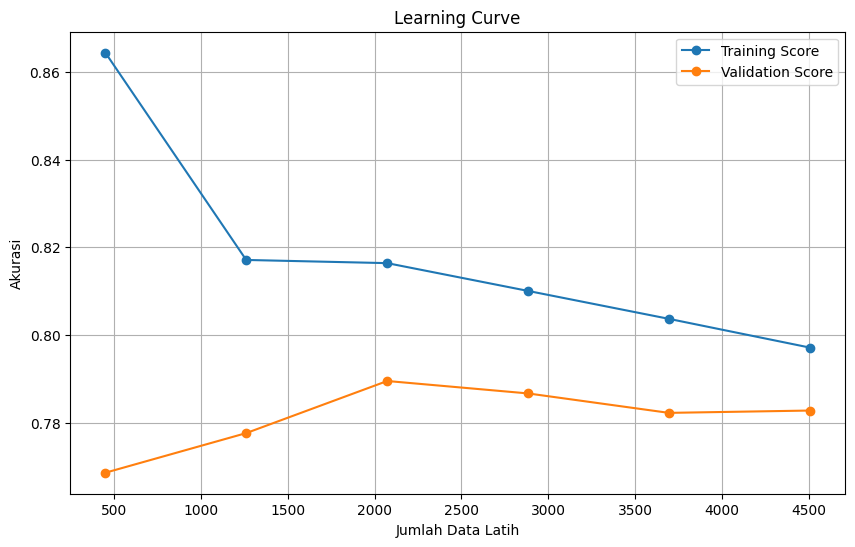

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_mean,
    '-o',
    label='Training Score'
)

plt.plot(
    train_sizes,
    val_mean,
    '-o',
    label='Validation Score'
)

plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)

plt.show()

Latihan Praktikum
1.   Praktikum 1: Memetakan Proyek Nyata ke CRISP-DM
# Tujuan: Mahasiswa mampu memetakan proyek ML nyata ke dalam 6 fase CRISP-DM.
Instruksi: Pilih satu studi kasus (misalnya prediksi churn pelanggan telekomunikasi
menggunakan dataset Telco Customer Churn dari Kaggle). Tuliskan aktivitas
konkret yang dilakukan pada masing-masing dari 6 fase CRISP-DM untuk kasus
tersebut.

2.   Praktikum 2: Diagnosis Bias-Variance
# Tujuan: Mahasiswa mampu membuat dan menginterpretasikan learning curve pada
model dengan kompleksitas berbeda.

In [ ]:
# Bandingkan learning curve untuk max_depth berbeda

for depth in [1, 4, None]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6),
        scoring="accuracy"
    )

    print(
        f"max_depth={depth}: "
        f"train={train_scores.mean():.3f}, "
        f"val={val_scores.mean():.3f}"
    )

max_depth=1: train=0.744, val=0.727
max_depth=4: train=0.818, val=0.781
max_depth=None: train=0.999, val=0.728


In [ ]:
# Menyimpan hasil learning curve
results = {}

for depth in [1, 4, None]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6),
        scoring="accuracy"
    )

    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    results[depth] = {
        "train_sizes": train_sizes,
        "train_mean": train_mean,
        "val_mean": val_mean
    }

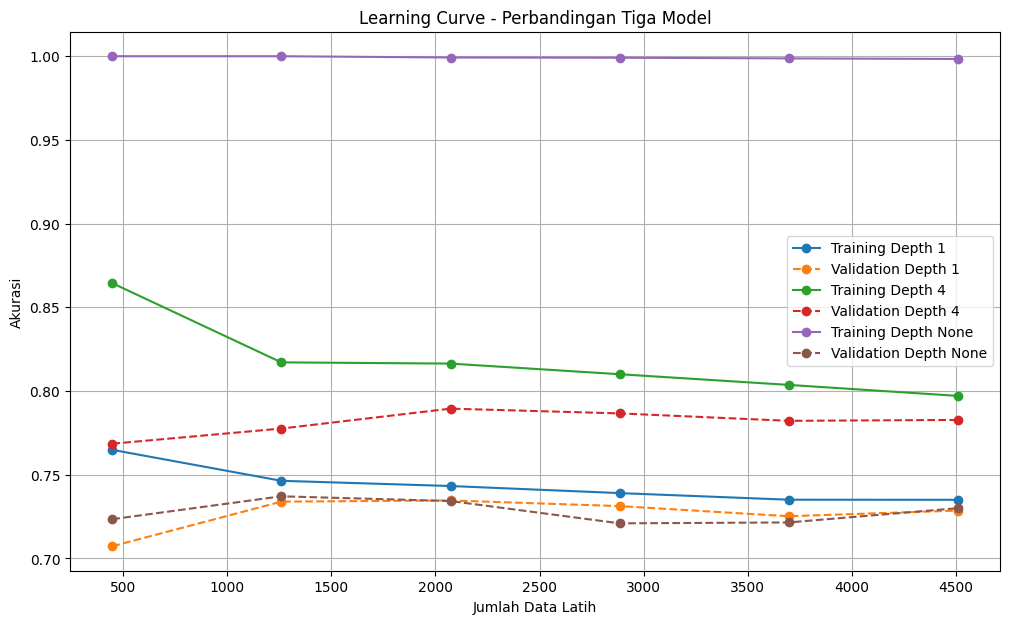

In [ ]:
plt.figure(figsize=(12, 7))

for depth in [1, 4, None]:

    train_sizes = results[depth]["train_sizes"]
    train_mean = results[depth]["train_mean"]
    val_mean = results[depth]["val_mean"]

    depth_name = "None" if depth is None else depth

    plt.plot(
        train_sizes,
        train_mean,
        '-o',
        label=f'Training Depth {depth_name}'
    )

    plt.plot(
        train_sizes,
        val_mean,
        '--o',
        label=f'Validation Depth {depth_name}'
    )

plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve - Perbandingan Tiga Model')

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
for depth in [1, 4, None]:

    train_mean = results[depth]["train_mean"]
    val_mean = results[depth]["val_mean"]

    train_score = train_mean[-1]
    val_score = val_mean[-1]

    gap = train_score - val_score

    print("=" * 50)

    print(f"Model max_depth = {depth}")
    print(f"Skor train      = {train_score:.3f}")
    print(f"Skor validasi   = {val_score:.3f}")
    print(f"Gap             = {gap:.3f}")



Model max_depth = 1
Skor train      = 0.735
Skor validasi   = 0.729
Gap             = 0.006
Model max_depth = 4
Skor train      = 0.797
Skor validasi   = 0.783
Gap             = 0.014
Model max_depth = None
Skor train      = 0.998
Skor validasi   = 0.730
Gap             = 0.268
